## 什麼是 Decision Tree Regression？

Decision Tree Regression 中文叫決策樹回歸，它是一種 Regression(迴歸) 模型，所以預測結果是連續數值，例如：

```text
房屋條件 → 房租
坪數、屋齡 → 房價
氣溫 → 用電量
廣告預算 → 銷售額
```

## 決策樹到底在做什麼
![](./assets/決策樹到底在做什麼.png)

## 決策樹怎麼衡量切得好不好？

![](./assets/決策樹怎麼衡量切得好不好.png)

## 實作

資料集："./data/decision_tree_rent_150.csv"

| 欄位 | 意義 | 用途 |
|---|---|---|
| `area_ping` | 房屋坪數 | Feature |
| `building_age` | 屋齡 | Feature |
| `rooms` | 房間數 | Feature |
| `monthly_rent` | 每月租金 | **Target** |

### 1. 讀取資料集


In [1]:
### Pandas 讀取資料
import pandas as pd


### 讀取房屋租金資料
df = pd.read_csv("./data/decision_tree_rent_150.csv") # 讀取 150 筆房屋資料

display(df.head())

,area_ping,building_age,rooms,monthly_rent
0,27.5,32,2,21484
1,57.4,0,5,43180
2,46.1,18,4,36368
3,39.1,1,3,29665
4,16.1,25,2,18131


### 2. 探索資料 (EDA)

先不要急著丟進模型，先確認資料長什麼樣


In [2]:
display(df.head())
### 確認資料的大小、欄位型態以及基本統計資訊
print("資料形狀：", df.shape)


### 查看資料型態與缺失值
df.info()


### 查看基本統計資料
display(df.describe())

display(df.isna().sum().rename("missing_count"))


,area_ping,building_age,rooms,monthly_rent
0,27.5,32,2,21484
1,57.4,0,5,43180
2,46.1,18,4,36368
3,39.1,1,3,29665
4,16.1,25,2,18131


資料形狀： (150, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_ping     150 non-null    float64
 1   building_age  150 non-null    int64  
 2   rooms         150 non-null    int64  
 3   monthly_rent  150 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 4.8 KB


,area_ping,building_age,rooms,monthly_rent
count,150.000000,150.000000,150.000000,150.000000
mean,32.587333,21.413333,2.826667,24299.426667
std,15.416148,11.974350,1.374488,10528.431125
min,8.300000,0.000000,1.000000,5976.000000
25%,19.125000,11.000000,2.000000,14380.750000
50%,31.300000,23.000000,3.000000,24088.000000
75%,47.000000,32.000000,4.000000,34054.250000
max,59.300000,40.000000,5.000000,44457.000000


area_ping       0
building_age    0
rooms           0
monthly_rent    0
Name: missing_count, dtype: int64

### 3. 資料清理 (Data Cleaning)


In [3]:
import numpy as np

required_columns = ["area_ping", "building_age", "rooms", "monthly_rent"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"資料缺少必要欄位：{missing_columns}")

rows_before = len(df)
df = df.copy()
for column in required_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df[required_columns] = df[required_columns].replace([np.inf, -np.inf], np.nan)

# 目標缺失時無法訓練；特徵缺失保留，稍後由 Pipeline 補值
df = df.dropna(subset=["monthly_rent"]).drop_duplicates().reset_index(drop=True)
print(f"清理前：{rows_before} 筆；清理後：{len(df)} 筆")
display(df[required_columns].isna().sum().rename("missing_count"))
if len(df) < 10:
    raise ValueError("清理後資料不足 10 筆，請檢查資料後再切分。")


清理前：150 筆；清理後：150 筆


area_ping       0
building_age    0
rooms           0
monthly_rent    0
Name: missing_count, dtype: int64

### 4. 選擇 Features 與 Target


這次模型的任務很明確：
$$
\boxed{
\text{area\_ping + building\_age + rooms}
\rightarrow
\text{預測 monthly\_rent}
}
$$
也就是：
- Features(X)：坪數、屋齡、房間數
- Target(y)：每月租金

In [4]:
### 設定 Features 與 Target
X = df[["area_ping", "building_age", "rooms"]].copy() # 房屋坪數、屋齡、房間數
y = df["monthly_rent"].copy() # 每月租金

### 5. 切分 Train / Test

保留 Validation 資料以比較樹深度；Train 60%、Validation 20%、Test 20%。


In [5]:
### 分割 Train、Validation、Test
from sklearn.model_selection import train_test_split


### 先切出 Test 20%
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


### 再從剩下的 80% 切出 Train 60%、Validation 20%
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42
)


### 查看資料筆數
print("Train：", len(X_train))
print("Validation：", len(X_valid))
print("Test：", len(X_test))

Train： 90
Validation： 30
Test： 30


### 6. 建立資料前處理 Pipeline


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 決策樹不需要標準化；中位數補值參數只從訓練資料學習
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True))
])


### 7. 建立模型


In [7]:
from sklearn.tree import DecisionTreeRegressor

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=5,     # 決策樹最多往下切 5 層
        random_state=42
    ))
])


### 8. 訓練模型


In [8]:
model.fit(X_train, y_train)
print("模型訓練完成")


模型訓練完成


### 9. 使用模型預測


In [9]:
y_valid_pred = model.predict(X_valid)
y_pred = model.predict(X_test)


### 10. 評估模型表現


In [10]:
### 驗收
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


### 計算 Validation 評估指標
mae = mean_absolute_error(y_valid, y_valid_pred)
mse = mean_squared_error(y_valid, y_valid_pred)
rmse = mse ** 0.5
r2 = r2_score(y_valid, y_valid_pred)


### 顯示結果
print("Validation MAE：", round(mae, 2))
print("Validation RMSE：", round(rmse, 2))
print("Validation R²：", round(r2, 4))

Validation MAE： 1729.4
Validation RMSE： 2402.31
Validation R²： 0.9514


In [11]:
# Test 資料用來評估固定 max_depth=5 的模型
print("Test MAE：", round(mean_absolute_error(y_test, y_pred), 2))
print("Test RMSE：", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print("Test R²：", round(r2_score(y_test, y_pred), 4))


Test MAE： 1495.5
Test RMSE： 1873.86
Test R²： 0.9679


In [12]:
from sklearn.base import clone

### 測試不同的 max_depth
result_list = []

for depth in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    candidate = clone(model).set_params(regressor__max_depth=depth)

    candidate.fit(X_train, y_train)

    train_pred = candidate.predict(X_train)
    valid_pred = candidate.predict(X_valid)

    train_mae = mean_absolute_error(y_train, train_pred)
    valid_mae = mean_absolute_error(y_valid, valid_pred)

    result_list.append({
        "max_depth": str(depth),
        "Train MAE": round(train_mae, 2),
        "Validation MAE": round(valid_mae, 2)
    })


### 轉成 DataFrame
result_df = pd.DataFrame(result_list)

display(result_df)

,max_depth,Train MAE,Validation MAE
0,1,4379.81,5791.93
1,2,2727.43,2995.53
2,3,1684.41,2113.55
3,4,1126.71,1881.10
4,5,845.03,1729.40
5,6,437.90,1959.97
6,8,44.16,1741.40
7,10,0.00,1646.23
8,None,0.00,1646.23


### 11. 視覺化預測結果


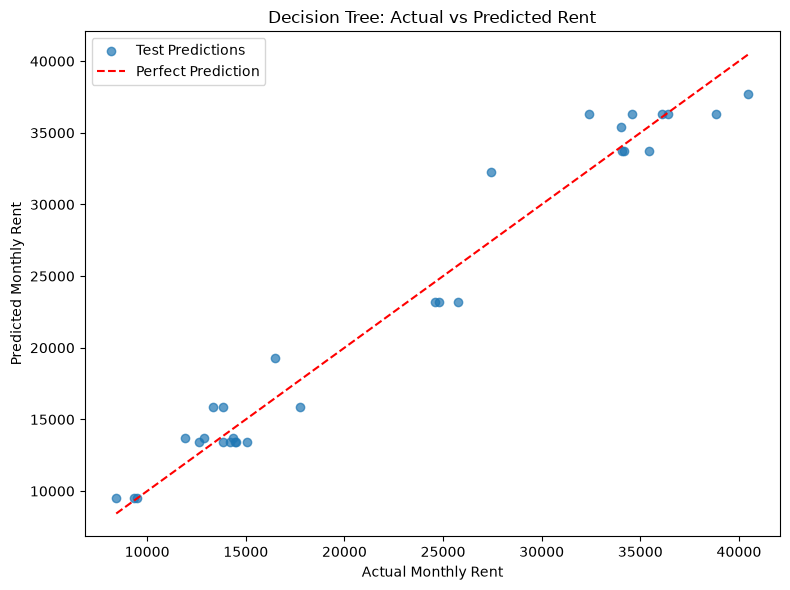

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, label="Test Predictions")
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Perfect Prediction")
plt.xlabel("Actual Monthly Rent")
plt.ylabel("Predicted Monthly Rent")
plt.title("Decision Tree: Actual vs Predicted Rent")
plt.legend()
plt.tight_layout()
plt.show()


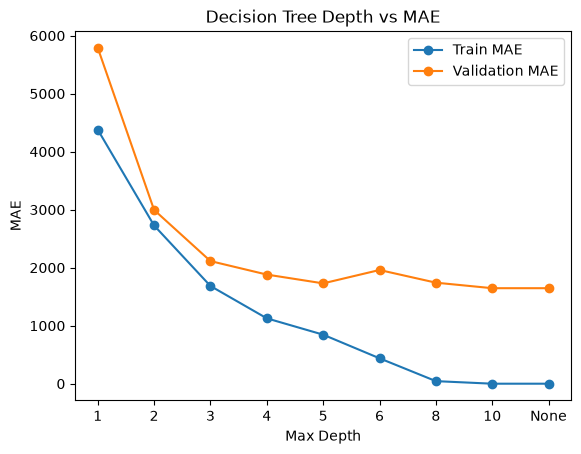

In [14]:
### 視覺化
import matplotlib.pyplot as plt


### 畫出不同 max_depth 的 Train / Validation MAE
plt.plot(
    result_df["max_depth"],
    result_df["Train MAE"],
    marker="o",
    label="Train MAE"
)

plt.plot(
    result_df["max_depth"],
    result_df["Validation MAE"],
    marker="o",
    label="Validation MAE"
)

plt.xlabel("Max Depth")
plt.ylabel("MAE")
plt.title("Decision Tree Depth vs MAE")
plt.legend()
plt.show()

## 作業：使用 Decision Tree Regression 預測高雄市房屋成交總價

本次作業使用政府資料開放平臺提供的「**高雄市115年不動產買賣實價登錄資料下載**」，並使用 **Decision Tree Regression(決策樹迴歸)** 建立模型，預測**房屋成交總價**。

資料集：政府資料開放平臺「高雄市115年不動產買賣實價登錄資料下載」：https://data.gov.tw/dataset/177586

模型會根據房屋的基本條件，例如：

```text id="l6ejys"
建物移轉面積
屋齡
房間數
客廳數
衛浴數
```

預測：

```text id="u74a4m"
房屋成交總價
```

也就是建立以下關係：

$$
\boxed{
\text{房屋基本條件}
\longrightarrow
\text{Decision Tree Regression}
\longrightarrow
\text{預測房屋成交總價}
}
$$

學生最後的 Notebook 必須按照以下順序完成：

```text id="4qqmmh"
1. 讀取資料集
        ↓
2. 探索資料 (EDA)
        ↓
3. 資料清理 (Data Cleaning)
        ↓
4. 選擇 Features 與 Target
        ↓
5. 切分 Train / Test
        ↓
6. 建立資料前處理 Pipeline
        ↓
7. 建立模型
        ↓
8. 訓練模型
        ↓
9. 使用模型預測
        ↓
10. 評估模型表現(MAE / RMSE / R²)
        ↓
11. 視覺化預測結果
```

<p style="text-align: center;">Copyright © 2026 Wei-Cheng Chen</p>